### Review Reply Workflow

A LLM based conditional workflow where we will analyse the sentiment of user review then reply according to it. we will have to paths ->
1. If review is negative then we will run diagnosis to find issue type, tone and urgency and then use these to write a reply for negative review.
2. If review is positive then we will write a reply for positive feedback

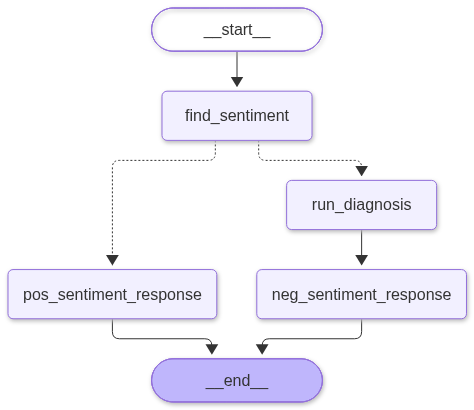

In [7]:
workflow

In [2]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from pydantic import BaseModel, Field
from typing import Literal, TypedDict
from dotenv import load_dotenv

In [3]:
load_dotenv()
model = ChatGroq(model='openai/gpt-oss-20b')

# create schema for structured output for sentiment
class SentimentSchema(BaseModel):
    sentiment: Literal['positive', 'negative'] = Field(description="sentiment for the user's review")

# schema for sttructured output for run diagnosis nodes
class DiagnosisSchema(BaseModel):
    issue_type: Literal['UI', 'Performance', 'Bug', 'Support', 'Other']
    tone: Literal['Frustrated', 'Angry', 'Disappointed', 'Neutral']
    urgency: Literal['Low', 'Medium', 'High']

structured_model1 = model.with_structured_output(SentimentSchema)
structured_model2 = model.with_structured_output(DiagnosisSchema)

In [4]:
# define state
class ReviewState(TypedDict):
    review: str
    sentiment: Literal['positive', 'negative']
    diagnosis: dict
    response: str

In [14]:
# write node functions
def find_sentiment(state: ReviewState) -> ReviewState:
    prompt = f"For the following review, find out the sentiment: {state['review']}"
    sentiment = structured_model1.invoke(prompt).sentiment
    return {'sentiment':sentiment}

# conditional function
def check_sentiment(state: ReviewState) -> Literal['run_diagnosis', 'pos_sentiment_response']:
    if state['sentiment'] == 'positive':
        return 'pos_sentiment_response'
    else:
        return 'run_diagnosis'

def run_diagnosis(state: ReviewState) -> ReviewState:
    prompt = f"Diagnose this negative review: {state['review']}. Return issue type, tone, and urgency."
    diagnosis = structured_model2.invoke(prompt)
    return {'diagnosis': diagnosis.model_dump()}

def pos_sentiment_response(state: ReviewState) -> ReviewState:
    prompt = f"Right a warm thank you message in response to this review-{state['review']}. Also kindly ask the user to leave feedback on our website."
    response = model.invoke(prompt).content
    return {'response': response}

def neg_sentiment_response(state: ReviewState) -> ReviewState:
    diagnosis = state['diagnosis']
    prompt = f"""You are a support assistant. The user had a {diagnosis['issue_type']} issue.
    The user sounded {diagnosis['tone']} and marked urgency as {diagnosis['urgency']}. Write an empathetic, helpful resolution message."""
    response = model.invoke(prompt).content
    return {'response': response}

In [15]:
# define graph
graph = StateGraph(ReviewState)

# define nodes
graph.add_node('find_sentiment', find_sentiment)
graph.add_node('run_diagnosis', run_diagnosis)
graph.add_node('pos_sentiment_response', pos_sentiment_response)
graph.add_node('neg_sentiment_response', neg_sentiment_response)

# defne edges 
graph.add_edge(START, 'find_sentiment')
graph.add_conditional_edges('find_sentiment', check_sentiment)
graph.add_edge('run_diagnosis', 'neg_sentiment_response')
graph.add_edge('neg_sentiment_response', END)
graph.add_edge('pos_sentiment_response', END)

# compile graph
workflow = graph.compile()

In [16]:
positive_review = """I've been using this product for a week now, and I am incredibly impressed.
The setup was a breeze, and the build quality feels premium and durable.
It performs exactly as advertised, and the battery life lasts much longer than my previous one.
What really stood out to me was the customer service—they responded to my query within an hour. Highly recommend it to anyone on the fence!"""

negative_review = """ I had high hopes for this, but it turned out to be a major letdown.
 The item arrived two days late, and the packaging was completely damaged.
 Once I got it running, it kept crashing every 10 minutes.
 The companion app is clunky, unresponsive, and constantly freezes.
I tried reaching out to support for a refund, but I haven't heard back. Save your money and look elsewhere."""

initial_state = {'review':positive_review}
final_state = workflow.invoke(initial_state)
final_state

{'review': "I've been using this product for a week now, and I am incredibly impressed.\nThe setup was a breeze, and the build quality feels premium and durable.\nIt performs exactly as advertised, and the battery life lasts much longer than my previous one.\nWhat really stood out to me was the customer service—they responded to my query within an hour. Highly recommend it to anyone on the fence!",
 'sentiment': 'positive',
 'response': 'Hi there!\n\nThank you so much for taking the time to share your experience. We’re thrilled to hear that the product met—and even exceeded—your expectations, and that our team could get back to you so quickly. Your kind words about the build quality, performance, and battery life truly warm our hearts.\n\nWe’re always looking to improve, and your feedback helps us keep delivering the best possible experience. If you have a moment, we’d be grateful if you could leave a quick review on our website—just click the link below and let us know what you think.

In [17]:
# example with negative response
workflow.invoke({'review':negative_review})

{'review': " I had high hopes for this, but it turned out to be a major letdown.\n The item arrived two days late, and the packaging was completely damaged.\n Once I got it running, it kept crashing every 10 minutes.\n The companion app is clunky, unresponsive, and constantly freezes.\nI tried reaching out to support for a refund, but I haven't heard back. Save your money and look elsewhere.",
 'sentiment': 'negative',
 'diagnosis': {'issue_type': 'Bug', 'tone': 'Frustrated', 'urgency': 'High'},
 'response': 'Hi there,\n\nI’m really sorry you’re running into this issue and I understand how frustrating it can be—especially when it’s happening right when you need it to work. I want to get this resolved for you as quickly as possible.\n\n**Here’s what we can do right now:**\n\n1. **Quick Check** –  \n   - Restart the application (or your device) to clear any temporary glitches.  \n   - Verify that you’re on the latest version (you can check for updates in Settings → About).  \n\n2. **Coll